#1
Churn reasons:  before 2023:online handling. after 2024 february: after 1 year, 2023 01-, TV, New York based, often sub for gifts
investigate in New York

Database: 
1. SubscriptionID  
2. HH Income 
3. Home Ownership 
4. Ethnicity 
5. dummy for Children 
6. Year Of Residence 
7. Age range 
8. Language 
9. Address 
10. State  
11. City 
12. County  
13. Zip Code 
14. monthly fee 
15. Device 
16. Nielsen Prizm 
17. Reward program (how many times did the subscriber use the reward program) 
18. Source Channel 
19. Subscriber

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
def load_data(file_path):
    try:
        data = pd.read_excel(file_path)
        return data
    except Exception as e:
        print(f"Error loading data: {e}")
        return None

file_path = 'ZenaraChurn.xlsx'

df = load_data(file_path)

df.head()

,SubscriptionID,HH Income,Home Ownership,Ethnicity,dummy for Children,Year Of Residence,Age range,Language,State,City,County,Zip Code,monthly fee,Device,Nielsen Prizm,reward program,Source Channel,Subscriber
0,181401653,"$500,000 Plus",OWNER,unknown,Y,14,50-54,NaN,NY,QUEENS VILLAGE,QUEENS,11379,$0.04-$2.00,Chrome,MW,0,Facebook Ads,YES
1,180374685,"$100,000 - $124,999",OWNER,Italian,Y,7,45-49,English,NY,FRESH MEADOWS,QUEENS,11358,$0.04-$2.00,Chrome,MW,0,Facebook Ads,YES
2,180358906,"$ 50,000 - $59,999",OWNER,Italian,N,23,60-64,English,NY,BELLEROSE,QUEENS,11425,$32.00-$35.96,Edge,MM,0,Google Ads,YES
3,140606609,"$150,000 - $174,999",OWNER,English,N,4,75 years or more,English,NY,BAYSIDE,QUEENS,11422,$8.00-$11.96,Opera,YW,0,Google Ads,NO
4,180571846,"$175,000 - $199,999",OWNER,Chinese,N,2,45-49,English,NY,BAYSIDE,QUEENS,11367,$8.00-$11.96,Chrome,MW,0,Kiosk,NO


1: Investigate the database, county and subscriber connection
Rewardprogram- Subcriber connection

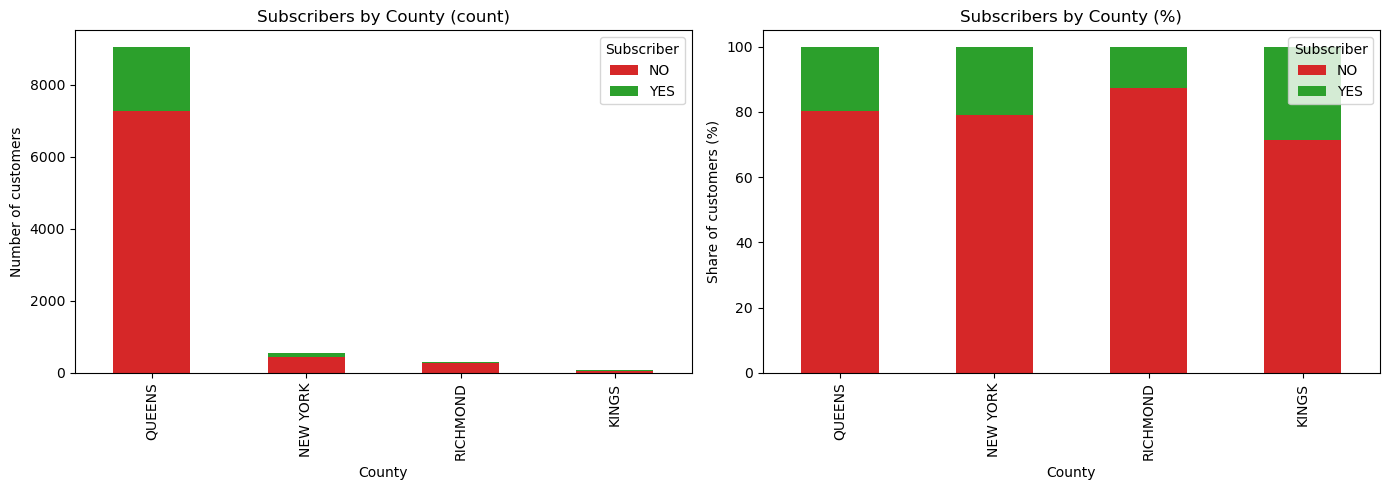

Subscriber,NO,YES
County,,
QUEENS,80.4,19.6
NEW YORK,79.1,20.9
RICHMOND,87.3,12.7
KINGS,71.4,28.6


In [2]:

#county and Subcriber stacked barchart
county_sub = pd.crosstab(df['County'], df['Subscriber'])
county_sub = county_sub.loc[county_sub.sum(axis=1).sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Counts
county_sub.plot(kind='bar', stacked=True, ax=axes[0], color=['#d62728', '#2ca02c'])
axes[0].set_title('Subscribers by County (count)')
axes[0].set_xlabel('County')
axes[0].set_ylabel('Number of customers')
axes[0].legend(title='Subscriber')

# Shares (100% stacked) - makes churn rates comparable across counties
county_share = county_sub.div(county_sub.sum(axis=1), axis=0) * 100
county_share.plot(kind='bar', stacked=True, ax=axes[1], color=['#d62728', '#2ca02c'])
axes[1].set_title('Subscribers by County (%)')
axes[1].set_xlabel('County')
axes[1].set_ylabel('Share of customers (%)')
axes[1].legend(title='Subscriber')

plt.tight_layout()
plt.show()

county_share.round(1)


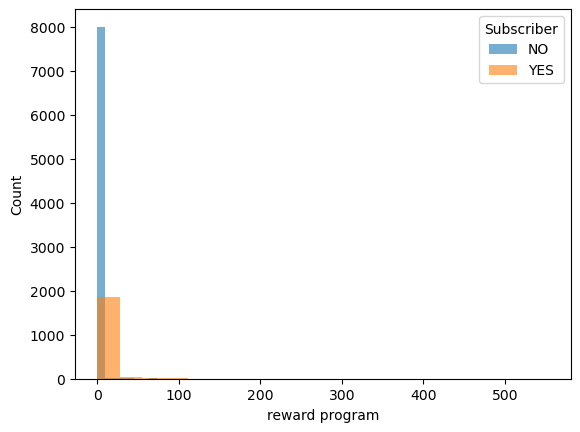

In [3]:
#reward program histogram colored by Subscriber
for value, group in df.groupby('Subscriber'):
    plt.hist(group['reward program'], bins=20, alpha=0.6, label=value)
plt.xlabel('reward program')
plt.ylabel('Count')
plt.legend(title='Subscriber')
plt.show()


In [4]:
#2 Modeling - data preparation
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

# Target (label) and features
y = df['Subscriber']
X = df.drop(columns=['Subscriber', 'SubscriptionID', 'Zip Code'])

# sklearn only accepts numbers: text columns -> 0/1 dummy columns
X = pd.get_dummies(X).fillna(0)

# Split Data: first 70% train, last 30% test (no shuffling)
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=False)
X_train.shape, X_test.shape


((7000, 276), (3000, 276))

In [5]:
#Decision tree - Gini
tree_gini = DecisionTreeClassifier(criterion='gini', max_depth=10, min_impurity_decrease=0.1)
tree_gini.fit(X_train, y_train)

pred = tree_gini.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(export_text(tree_gini, feature_names=list(X.columns)))


Accuracy: 0.8096666666666666
[[2429    0]
 [ 571    0]]
|--- class: NO



In [6]:
#Decision tree - Gain ratio (sklearn closest option: entropy = information gain)
tree_gain = DecisionTreeClassifier(criterion='entropy', max_depth=10, min_impurity_decrease=0.1)
tree_gain.fit(X_train, y_train)

pred = tree_gain.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))
print(export_text(tree_gain, feature_names=list(X.columns)))


Accuracy: 0.8096666666666666
[[2429    0]
 [ 571    0]]
|--- class: NO



In [7]:
#Naive Bayes
nb = GaussianNB()
nb.fit(X_train, y_train)

pred = nb.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))
print(confusion_matrix(y_test, pred))


Accuracy: 0.3396666666666667
[[ 464 1965]
 [  16  555]]


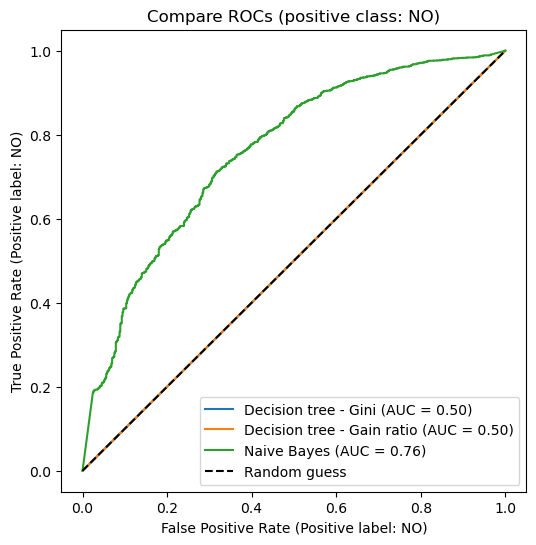

In [8]:
#Compare ROCs - same X_test / y_test as the confusion matrices, positive class = NO (churner)
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 6))
for name, model in [('Decision tree - Gini', tree_gini), ('Decision tree - Gain ratio', tree_gain), ('Naive Bayes', nb)]:
    RocCurveDisplay.from_estimator(model, X_test, y_test, pos_label='NO', name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.set_title('Compare ROCs (positive class: NO)')
ax.legend()
plt.show()
